# TA-07: Q-Learning pada Agen Kurir Pengiriman Paket (Taxi Problem)

**Mata Praktikum:** Pembelajaran Mesin | **Modul 07:** Reinforcement Learning

Notebook ini berisi implementasi **Langkah 1-5** TA-07:
1. Persiapan environment (simulasi Python murni, tanpa Gymnasium)
2. Implementasi Q-Learning (Persamaan Bellman + epsilon-greedy)
3. Analisis konvergensi (kurva pembelajaran)
4. Analisis dan interpretasi kebijakan (policy)
5. Eksperimen hiperparameter

**Skenario:** seorang kurir bergerak di grid kota 5x5. Ia harus menjemput paket di salah satu
dari 4 titik (R, G, Y, B), lalu mengantarkannya ke salah satu dari 4 titik tujuan.


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

os.makedirs("output", exist_ok=True)
SEED = 42

## Langkah 1: Persiapan Environment

**Definisi S, A, R**

| Elemen | Definisi |
|---|---|
| **State (S)** | (baris kurir, kolom kurir, lokasi paket, tujuan) = 5 x 5 x 5 x 4 = **500 state**. Lokasi paket bernilai 0-3 (menunggu di R/G/Y/B) atau 4 (sudah di dalam kendaraan). Tujuan bernilai 0-3. |
| **Action (A)** | 6 aksi: 0 = Selatan, 1 = Utara, 2 = Timur, 3 = Barat, 4 = Ambil paket, 5 = Antar paket |
| **Reward (R)** | -1 untuk setiap langkah, +20 jika paket berhasil diantar ke tujuan yang benar, -10 jika Ambil/Antar dilakukan di tempat yang salah |

Environment dibuat sebagai kelas Python dengan fungsi `step(action)` yang mengembalikan
`new_state, reward, done`.

In [2]:
class TaxiEnv:
    """Environment kurir pengiriman paket di grid 5x5."""

    GRID = 5
    PICKUPS = [(0, 0), (0, 4), (4, 0), (4, 4)]   # R, G, Y, B (baris, kolom)
    NAMES = ["R", "G", "Y", "B"]
    ACTIONS = ["Selatan", "Utara", "Timur", "Barat", "Ambil", "Antar"]

    def __init__(self, seed=None):
        self.n_states = self.GRID * self.GRID * 5 * 4   # 500
        self.n_actions = len(self.ACTIONS)               # 6
        self.rng = np.random.default_rng(seed)
        self.state = None

    # --- encode/decode state <-> integer 0..499 ---
    @staticmethod
    def encode(row, col, pass_loc, dest):
        return ((row * 5 + col) * 5 + pass_loc) * 4 + dest

    @staticmethod
    def decode(s):
        dest = s % 4
        s //= 4
        pass_loc = s % 5
        s //= 5
        col = s % 5
        row = s // 5
        return row, col, pass_loc, dest

    def reset(self):
        """Mulai episode baru: posisi kurir, lokasi paket, dan tujuan diacak."""
        row = int(self.rng.integers(self.GRID))
        col = int(self.rng.integers(self.GRID))
        pass_loc = int(self.rng.integers(4))
        dest = int(self.rng.integers(4))
        while dest == pass_loc:          # tujuan tidak boleh sama dengan lokasi paket
            dest = int(self.rng.integers(4))
        self.state = self.encode(row, col, pass_loc, dest)
        return self.state

    def step(self, action):
        """Jalankan satu aksi. Mengembalikan (new_state, reward, done)."""
        row, col, pass_loc, dest = self.decode(self.state)
        reward, done = -1, False

        if action == 0:
            row = min(row + 1, self.GRID - 1)
        elif action == 1:
            row = max(row - 1, 0)
        elif action == 2:
            col = min(col + 1, self.GRID - 1)
        elif action == 3:
            col = max(col - 1, 0)
        elif action == 4:                                   # Ambil paket
            if pass_loc < 4 and (row, col) == self.PICKUPS[pass_loc]:
                pass_loc = 4
            else:
                reward = -10
        elif action == 5:                                   # Antar paket
            if pass_loc == 4 and (row, col) == self.PICKUPS[dest]:
                reward, done = 20, True
            else:
                reward = -10

        self.state = self.encode(row, col, pass_loc, dest)
        return self.state, reward, done

Uji singkat environment: lakukan beberapa aksi acak dan lihat hasilnya.

In [3]:
def uji_environment():
    env = TaxiEnv(seed=SEED)
    s = env.reset()
    print("State awal:", s, "->", env.decode(s), "(baris, kolom, lokasi paket, tujuan)")
    for _ in range(5):
        a = int(env.rng.integers(env.n_actions))
        s, r, done = env.step(a)
        print(f"aksi={TaxiEnv.ACTIONS[a]:8s} reward={r:4d} done={done} state={env.decode(s)}")

## Langkah 2: Implementasi Q-Learning

- **Q-Table:** matriks 500 x 6, diinisialisasi nol.
- **Persamaan Bellman:** `Q(s,a) <- (1 - alpha) * Q(s,a) + alpha * [r + gamma * max Q(s',a')]`
- **Epsilon-greedy:** epsilon mulai 1.0 lalu menurun eksponensial hingga `eps_min`.
- Pada state terminal (paket berhasil diantar), target Q hanya reward saja, tanpa suku `gamma * max Q(s')`.

In [4]:
HP = dict(
    episodes=5000,
    alpha=0.8,         # learning rate
    gamma=0.9,         # discount factor
    eps_start=1.0,
    eps_min=0.01,
    decay_rate=0.001,  # laju penurunan epsilon
    max_steps=200,     # batas langkah per episode
)


def train_q_learning(env, episodes, alpha, gamma, eps_start, eps_min,
                     decay_rate, max_steps, seed=SEED, verbose=True):
    rng = np.random.default_rng(seed)
    q = np.zeros((env.n_states, env.n_actions))
    rewards, eps_hist, success = [], [], []
    eps = eps_start

    for ep in range(episodes):
        s = env.reset()
        total, delivered = 0, False

        for _ in range(max_steps):
            # 1. Pilih aksi: epsilon-greedy (tie-break acak saat nilai Q sama)
            if rng.random() < eps:
                a = int(rng.integers(env.n_actions))            # eksplorasi
            else:
                best = np.flatnonzero(q[s] == q[s].max())
                a = int(rng.choice(best))                       # eksploitasi

            # 2. Lakukan aksi
            s2, r, done = env.step(a)

            # 3. Update Q-Table (Persamaan Bellman)
            target = r if done else r + gamma * np.max(q[s2])
            q[s, a] = (1 - alpha) * q[s, a] + alpha * target

            s, total = s2, total + r
            if done:
                delivered = True
                break

        rewards.append(total)
        success.append(delivered)
        eps_hist.append(eps)
        # 4. Turunkan epsilon
        eps = eps_min + (eps_start - eps_min) * np.exp(-decay_rate * (ep + 1))

        if verbose and (ep + 1) % 1000 == 0:
            print(f"Episode {ep + 1:5d} | rata-rata reward (100 terakhir) = "
                  f"{np.mean(rewards[-100:]):7.2f} | epsilon = {eps_hist[-1]:.3f}")

    return dict(q=q, rewards=np.array(rewards), eps=np.array(eps_hist),
                success=np.array(success))

## Langkah 3: Analisis Konvergensi

Total reward per episode dicatat selama pelatihan, lalu dihaluskan dengan *moving average* (window 100).

In [5]:
def moving_average(x, window=100):
    return pd.Series(x).rolling(window=window, min_periods=1).mean().to_numpy()


def find_convergence(ma, tail=500, tol=0.1, min_band=2.0):
    """Episode pertama setelah mana moving average tetap berada dalam pita
    +/- max(min_band, tol*|nilai akhir|) di sekitar nilai akhir."""
    final = float(np.mean(ma[-tail:]))
    band = max(min_band, tol * abs(final))
    outside = np.flatnonzero(np.abs(ma - final) > band)
    return (int(outside[-1]) + 1 if len(outside) else 0), final


def plot_learning_curves(runs, window=100, title="Kurva Pembelajaran Q-Learning",
                         save_path=None, show_epsilon=False):
    fig, ax = plt.subplots(figsize=(10, 6))
    for label, res in runs.items():
        ax.plot(moving_average(res["rewards"], window), label=label)
    ax.set_title(f"{title} (Rata-Rata {window} Episode)")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Rata-Rata Total Reward")
    ax.grid(True)
    if show_epsilon:
        ax2 = ax.twinx()
        first = next(iter(runs.values()))
        ax2.plot(first["eps"], color="gray", linestyle="--", alpha=0.6, label="epsilon")
        ax2.set_ylabel("Epsilon")
    ax.legend(loc="lower right")
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

## Langkah 4: Analisis dan Interpretasi Kebijakan (Policy)

Kebijakan optimal diambil dengan `argmax_a Q(s,a)` untuk setiap state. Karena state terdiri dari 4 fitur,
policy divisualisasikan per kombinasi (lokasi paket, tujuan): satu peta 5x5 untuk fase *menuju paket*
dan satu peta untuk fase *mengantar paket*. Sel kuning adalah target saat itu.

In [6]:
ARROW = {0: "↓", 1: "↑", 2: "→", 3: "←", 4: "P", 5: "D"}   # P = Ambil, D = Antar


def extract_policy(q):
    return np.argmax(q, axis=1)


def plot_policy(q, pass_loc, dest, ax=None, title=None):
    n = TaxiEnv.GRID
    if ax is None:
        _, ax = plt.subplots(figsize=(4.5, 4.5))
    target = TaxiEnv.PICKUPS[pass_loc] if pass_loc < 4 else TaxiEnv.PICKUPS[dest]

    for r in range(n):
        for c in range(n):
            color = "white"
            if (r, c) in TaxiEnv.PICKUPS:
                color = "#dbeafe"
            if (r, c) == target:
                color = "#fde68a"
            ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor=color, edgecolor="gray"))
            if (r, c) in TaxiEnv.PICKUPS:
                ax.text(c + 0.08, r + 0.22, TaxiEnv.NAMES[TaxiEnv.PICKUPS.index((r, c))],
                        fontsize=9, color="#1d4ed8", fontweight="bold")
            s = TaxiEnv.encode(r, c, pass_loc, dest)
            sym = "·" if q[s].max() == q[s].min() else ARROW[int(np.argmax(q[s]))]
            ax.text(c + 0.5, r + 0.55, sym, ha="center", va="center", fontsize=20)

    ax.set_xlim(0, n)
    ax.set_ylim(n, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)


def plot_policies(q, save_path=None):
    N = TaxiEnv.NAMES
    kasus = [(0, 1), (4, 1), (2, 3), (4, 3)]   # (lokasi paket, tujuan)
    fig, axes = plt.subplots(2, 2, figsize=(9, 9))
    for ax, (p, d) in zip(axes.ravel(), kasus):
        if p < 4:
            judul = f"Fase 1: menuju paket di {N[p]} (tujuan {N[d]})"
        else:
            judul = f"Fase 2: antar paket ke {N[d]} (paket di kendaraan)"
        plot_policy(q, p, d, ax=ax, title=judul)
    fig.suptitle("Kebijakan Optimal yang Dipelajari (←↑→↓ gerak, P = Ambil, D = Antar)")
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def evaluate_policy(q, n_episodes=200, max_steps=200, seed=123):
    """Evaluasi mode eksploitasi murni (greedy, tanpa eksplorasi)."""
    env = TaxiEnv(seed=seed)
    rewards, steps, ok = [], [], []
    for _ in range(n_episodes):
        s = env.reset()
        total, done = 0, False
        for t in range(1, max_steps + 1):
            s, r, done = env.step(int(np.argmax(q[s])))
            total += r
            if done:
                break
        rewards.append(total)
        ok.append(done)
        if done:
            steps.append(t)
    return dict(success_rate=float(np.mean(ok)),
                avg_reward=float(np.mean(rewards)),
                avg_steps=float(np.mean(steps)) if steps else float("nan"))


def demo_episode(q, seed=7, max_steps=40):
    """Cetak satu episode greedy langkah demi langkah."""
    env = TaxiEnv(seed=seed)
    s = env.reset()
    rows = []
    for t in range(1, max_steps + 1):
        r_, c_, p, d = TaxiEnv.decode(s)
        a = int(np.argmax(q[s]))
        s, r, done = env.step(a)
        rows.append(dict(langkah=t, posisi=(r_, c_),
                         paket="di kendaraan" if p == 4 else TaxiEnv.NAMES[p],
                         tujuan=TaxiEnv.NAMES[d], aksi=TaxiEnv.ACTIONS[a], reward=r))
        if done:
            break
    return pd.DataFrame(rows)

## Analisis Tambahan (dipakai di laporan)

Tiga fungsi berikut menghitung angka-angka yang dikutip di laporan, supaya semua angka dapat
direproduksi dengan menjalankan notebook ini:
- `training_summary`: reward moving average pada beberapa episode, titik pertama melewati nol,
  simpangan baku reward, dan tingkat keberhasilan selama pelatihan.
- `route_analysis`: menguji kebijakan greedy dari seluruh 400 state awal yang mungkin dan membandingkan
  panjang rutenya dengan batas bawah dari jarak Manhattan.
- `q_table_terisi`: jumlah state yang nilai Q-nya sudah terisi.

In [7]:
def training_summary(res, checkpoints=(100, 250, 500, 1000, 2000, 3000, 3474, 5000)):
    r, s, e = res["rewards"], res["success"], res["eps"]
    ma = moving_average(r, 100)
    tabel = pd.DataFrame([dict(episode=ep, ma100=round(float(ma[ep - 1]), 2),
                               epsilon=round(float(e[ep - 1]), 3)) for ep in checkpoints])
    info = dict(
        pertama_melewati_nol=int(np.argmax(ma > 0)) + 1,
        std_500_pertama=float(np.std(r[:500])),
        std_500_terakhir=float(np.std(r[-500:])),
        sukses_100_pertama=float(np.mean(s[:100])),
        sukses_episode_151_250=float(np.mean(s[150:250])),
        sukses_pelatihan_per_100={ep: float(np.mean(s[ep - 100:ep])) for ep in (1000, 2000, 3000, 4000, 5000)},
    )
    return tabel, info


def _manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def route_analysis(q, max_steps=200):
    """Uji kebijakan greedy dari semua state awal yang mungkin (paket menunggu = fase 1,
    paket di kendaraan = fase 2) dan bandingkan dengan jumlah langkah minimum."""
    P = TaxiEnv.PICKUPS
    stat = {"menunggu": dict(n=0, sukses=0, terpendek=0), "kendaraan": dict(n=0, sukses=0, terpendek=0)}
    lebih_panjang = []
    for row in range(5):
        for col in range(5):
            for p in range(5):
                for d in range(4):
                    if p == d:
                        continue
                    env = TaxiEnv(seed=0)
                    s = env.state = TaxiEnv.encode(row, col, p, d)
                    n, done = 0, False
                    while n < max_steps and not done:
                        s, _, done = env.step(int(np.argmax(q[s])))
                        n += 1
                    minimum = (_manhattan((row, col), P[p]) + 1 + _manhattan(P[p], P[d]) + 1
                               if p < 4 else _manhattan((row, col), P[d]) + 1)
                    k = stat["menunggu" if p < 4 else "kendaraan"]
                    k["n"] += 1
                    k["sukses"] += int(done)
                    k["terpendek"] += int(done and n == minimum)
                    if done and n > minimum:
                        lebih_panjang.append(dict(baris=row, kolom=col, paket=p, tujuan=d,
                                                  langkah=n, minimum=minimum))
    total = {k: stat["menunggu"][k] + stat["kendaraan"][k] for k in ("n", "sukses", "terpendek")}
    return dict(menunggu=stat["menunggu"], kendaraan=stat["kendaraan"], total=total,
                lebih_panjang=pd.DataFrame(lebih_panjang))


def q_table_terisi(q):
    return int((q != 0).any(axis=1).sum())

---
## Menjalankan Langkah 1-4
(Pada skrip `.py`, bagian di bawah ini dijalankan lewat `python ta07_taxi_qlearning.py`.)

In [8]:
# --- Langkah 1: uji environment ---
uji_environment()

State awal: 69 -> (0, 3, 2, 1) (baris, kolom, lokasi paket, tujuan)
aksi=Timur    reward=  -1 done=False state=(0, 4, 2, 1)
aksi=Antar    reward= -10 done=False state=(0, 4, 2, 1)
aksi=Selatan  reward=  -1 done=False state=(1, 4, 2, 1)
aksi=Ambil    reward= -10 done=False state=(1, 4, 2, 1)
aksi=Utara    reward=  -1 done=False state=(0, 4, 2, 1)


### Pelatihan (Langkah 2)

In [9]:
env = TaxiEnv(seed=SEED)
hasil = train_q_learning(env, **HP)
q_table = hasil["q"]
print("\nBentuk Q-Table:", q_table.shape)

Episode  1000 | rata-rata reward (100 terakhir) =  -22.96 | epsilon = 0.375
Episode  2000 | rata-rata reward (100 terakhir) =    0.38 | epsilon = 0.144


Episode  3000 | rata-rata reward (100 terakhir) =    7.92 | epsilon = 0.059
Episode  4000 | rata-rata reward (100 terakhir) =    8.11 | epsilon = 0.028


Episode  5000 | rata-rata reward (100 terakhir) =    8.72 | epsilon = 0.017

Bentuk Q-Table: (500, 6)


### Kurva pembelajaran (Langkah 3)

**Pertanyaan untuk analisis laporan:** pada episode ke berapa kurva mulai datar? Apa arti fluktuasi
besar di awal pelatihan? (Petunjuk: pada awal pelatihan epsilon ~ 1, sehingga kurir bergerak hampir acak
dan sering terkena penalti -10 serta mencapai batas langkah.)

Konvergensi (datar) mulai sekitar episode ke-3474, dengan rata-rata reward ~ 8.97
Reward rata-rata 100 episode pertama : -690.12
Reward rata-rata 100 episode terakhir: 8.72


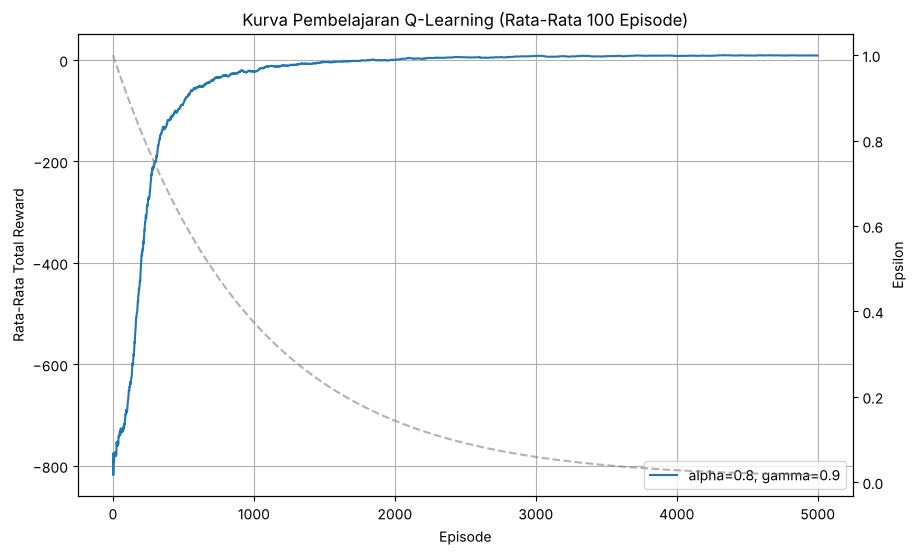

In [10]:
ma = moving_average(hasil["rewards"], 100)
ep_konv, nilai_akhir = find_convergence(ma)
print(f"Konvergensi (datar) mulai sekitar episode ke-{ep_konv}, "
      f"dengan rata-rata reward ~ {nilai_akhir:.2f}")
print(f"Reward rata-rata 100 episode pertama : {np.mean(hasil['rewards'][:100]):.2f}")
print(f"Reward rata-rata 100 episode terakhir: {np.mean(hasil['rewards'][-100:]):.2f}")
plot_learning_curves({"alpha=0.8, gamma=0.9": hasil}, window=100,
                     save_path="output/kurva_pembelajaran.png", show_epsilon=True)

### Kebijakan optimal (Langkah 4)

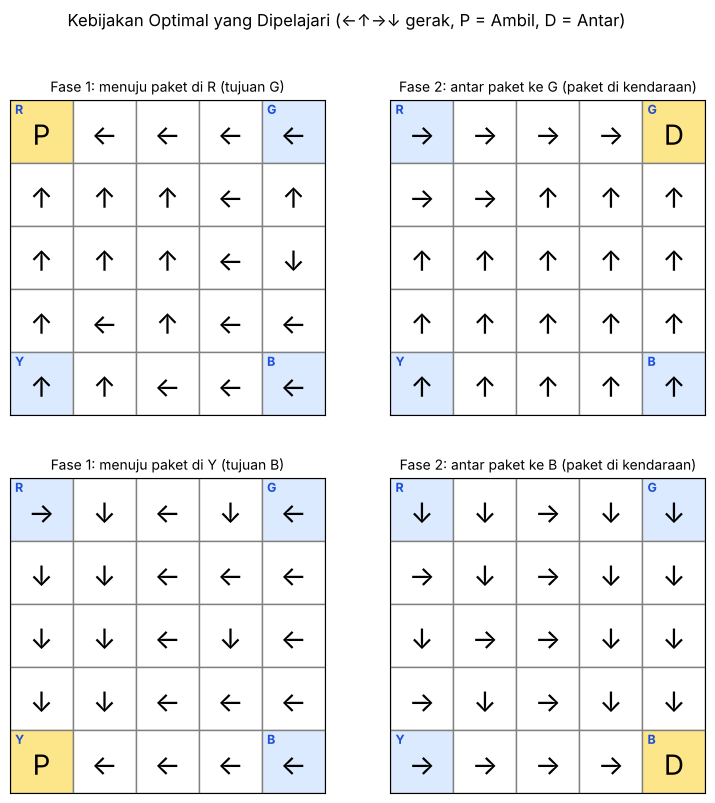

In [11]:
plot_policies(q_table, save_path="output/kebijakan_optimal.png")

In [12]:
hasil_eval = evaluate_policy(q_table)
print("Evaluasi greedy (200 episode):")
print(f"  Tingkat keberhasilan : {hasil_eval['success_rate'] * 100:.1f}%")
print(f"  Rata-rata reward     : {hasil_eval['avg_reward']:.2f}")
print(f"  Rata-rata langkah    : {hasil_eval['avg_steps']:.1f}")

Evaluasi greedy (200 episode):
  Tingkat keberhasilan : 100.0%
  Rata-rata reward     : 9.35
  Rata-rata langkah    : 11.7


**Jejak satu episode** (untuk menjelaskan alur berpikir agen di laporan/video):

In [13]:
print(demo_episode(q_table).to_string(index=False))

 langkah posisi        paket tujuan  aksi  reward
       1 (4, 3)            Y      B Barat      -1
       2 (4, 2)            Y      B Barat      -1
       3 (4, 1)            Y      B Barat      -1
       4 (4, 0)            Y      B Ambil      -1
       5 (4, 0) di kendaraan      B Timur      -1
       6 (4, 1) di kendaraan      B Timur      -1
       7 (4, 2) di kendaraan      B Timur      -1
       8 (4, 3) di kendaraan      B Timur      -1
       9 (4, 4) di kendaraan      B Antar      20


### Angka pendukung laporan (Langkah 3 dan 4)

In [14]:
tabel_cp, info = training_summary(hasil)
print("Reward moving average pada beberapa episode:")
print(tabel_cp.to_string(index=False))
print(f"\nPertama kali MA-100 melewati nol : episode {info['pertama_melewati_nol']}")
print(f"Simpangan baku reward            : {info['std_500_pertama']:.1f} (500 episode pertama) -> "
      f"{info['std_500_terakhir']:.1f} (500 episode terakhir)")
print(f"Episode berhasil mengantar paket : {info['sukses_100_pertama'] * 100:.0f}% (episode 1-100), "
      f"{info['sukses_episode_151_250'] * 100:.0f}% (episode 151-250)")
print(f"State dengan nilai Q terisi      : {q_table_terisi(q_table)} dari {env.n_states}")

Reward moving average pada beberapa episode:
 episode   ma100  epsilon
     100 -690.12    0.907
     250 -275.93    0.782
     500  -85.78    0.611
    1000  -22.96    0.375
    2000    0.38    0.144
    3000    7.92    0.059
    3474    6.95    0.041
    5000    8.72    0.017

Pertama kali MA-100 melewati nol : episode 1822
Simpangan baku reward            : 275.9 (500 episode pertama) -> 3.9 (500 episode terakhir)
Episode berhasil mengantar paket : 22% (episode 1-100), 93% (episode 151-250)
State dengan nilai Q terisi      : 400 dari 500


In [15]:
ra = route_analysis(q_table)
t, m, k = ra["total"], ra["menunggu"], ra["kendaraan"]
print("Uji kebijakan greedy dari semua state awal yang mungkin:")
print(f"  Berhasil mengantar paket   : {t['sukses']} dari {t['n']}")
print(f"  Rute dengan langkah minimum: {t['terpendek']} dari {t['n']} ({t['terpendek'] / t['n'] * 100:.1f}%)")
print(f"    paket menunggu           : {m['terpendek']} dari {m['n']} (berhasil {m['sukses']})")
print(f"    paket di kendaraan       : {k['terpendek']} dari {k['n']} (berhasil {k['sukses']})")
print("\nState awal dengan rute lebih panjang dari minimum:")
print(ra["lebih_panjang"].to_string(index=False))

Uji kebijakan greedy dari semua state awal yang mungkin:
  Berhasil mengantar paket   : 400 dari 400
  Rute dengan langkah minimum: 394 dari 400 (98.5%)
    paket menunggu           : 294 dari 300 (berhasil 300)
    paket di kendaraan       : 100 dari 100 (berhasil 100)

State awal dengan rute lebih panjang dari minimum:
 baris  kolom  paket  tujuan  langkah  minimum
     0      0      1       0       12       10
     0      0      2       0       12       10
     0      0      2       3       12       10
     2      4      0       1       14       12
     4      0      3       0       16       14
     4      4      1       0       12       10


In [16]:
np.save("output/q_table.npy", q_table)

## Langkah 5: Eksperimen Hiperparameter

Pilih **satu** hiperparameter saja (`gamma` ATAU `alpha`), lalu latih model dengan nilai default (tinggi)
dan nilai ekstrem (sangat rendah). Untuk `gamma`, nilai menengah 0,1 ikut diuji sebagai pembanding.

- **gamma rendah:** agen menjadi *miopik*, hanya peduli reward instan. Reward +20 saat antar paket
  tidak "terasa" dari state yang jauh, sehingga agen sulit belajar rute panjang.
- **alpha rendah:** pembelajaran sangat lambat karena nilai Q hanya bergeser sedikit tiap update.
  (alpha terlalu tinggi bisa membuat Q-Table tidak stabil.)

**Catatan:** pada environment deterministik ini, gamma = 0.1 ternyata masih berhasil, karena selisih
nilai Q yang kecil tetap terbaca oleh `argmax`. Efek "miopik" baru jelas pada nilai yang jauh lebih
rendah (0.01 atau 0.0), sehingga nilai ekstrem yang dipakai adalah 0.01.

In [17]:
PARAM = "gamma"   # ganti ke "alpha" untuk eksperimen learning rate
EKSPERIMEN = {
    # urutan: default (tinggi) -> menengah (opsional) -> ekstrem (sangat rendah)
    "gamma": {"default": 0.9, "menengah": 0.1, "ekstrem": 0.01},
    "alpha": {"default": 0.8, "ekstrem": 0.01},
}


def jalankan_eksperimen(param):
    runs, ringkasan, detail = {}, [], []
    for jenis, nilai in EKSPERIMEN[param].items():
        hp = dict(HP)
        hp[param] = nilai
        label = f"{param}={nilai} ({jenis})"
        print(f"\n=== Pelatihan: {label} ===")
        env = TaxiEnv(seed=SEED)
        res = train_q_learning(env, seed=SEED, **hp)
        runs[label] = res

        ma = moving_average(res["rewards"], 100)
        ep_konv, _ = find_convergence(ma)
        ev = evaluate_policy(res["q"])
        ra = route_analysis(res["q"])
        _, info = training_summary(res)
        t, m, k = ra["total"], ra["menunggu"], ra["kendaraan"]
        ringkasan.append({
            "Model": label,
            "Reward 100 ep. terakhir": round(float(np.mean(res["rewards"][-100:])), 2),
            "Konvergensi (episode)": ep_konv,
            "Sukses greedy (%)": round(ev["success_rate"] * 100, 1),
            "Reward greedy": round(ev["avg_reward"], 2),
            "Langkah rata-rata": round(ev["avg_steps"], 1),
        })
        detail.append({
            "Model": label,
            "State awal berhasil": f"{t['sukses']}/{t['n']}",
            "Rute terpendek": f"{t['terpendek']}/{t['n']}",
            "Paket menunggu (berhasil)": f"{m['sukses']}/{m['n']}",
            "Paket di kendaraan (berhasil)": f"{k['sukses']}/{k['n']}",
            "Sukses saat pelatihan, per 100 ep. (ep. 1000-5000)":
                " / ".join(f"{v * 100:.0f}%" for v in info["sukses_pelatihan_per_100"].values()),
        })
    return runs, pd.DataFrame(ringkasan), pd.DataFrame(detail)

In [18]:
runs, tabel, detail = jalankan_eksperimen(PARAM)


=== Pelatihan: gamma=0.9 (default) ===


Episode  1000 | rata-rata reward (100 terakhir) =  -22.96 | epsilon = 0.375
Episode  2000 | rata-rata reward (100 terakhir) =    0.38 | epsilon = 0.144


Episode  3000 | rata-rata reward (100 terakhir) =    7.92 | epsilon = 0.059
Episode  4000 | rata-rata reward (100 terakhir) =    8.11 | epsilon = 0.028


Episode  5000 | rata-rata reward (100 terakhir) =    8.72 | epsilon = 0.017

=== Pelatihan: gamma=0.1 (menengah) ===


Episode  1000 | rata-rata reward (100 terakhir) =  -22.11 | epsilon = 0.375
Episode  2000 | rata-rata reward (100 terakhir) =    2.06 | epsilon = 0.144


Episode  3000 | rata-rata reward (100 terakhir) =    6.68 | epsilon = 0.059
Episode  4000 | rata-rata reward (100 terakhir) =    7.50 | epsilon = 0.028


... (2 outputs left out)

Episode  2000 | rata-rata reward (100 terakhir) =  -64.22 | epsilon = 0.144


Episode  3000 | rata-rata reward (100 terakhir) =  -37.59 | epsilon = 0.059


Episode  4000 | rata-rata reward (100 terakhir) =  -50.51 | epsilon = 0.028


Episode  5000 | rata-rata reward (100 terakhir) =  -38.48 | epsilon = 0.017


### Perbandingan kurva pembelajaran

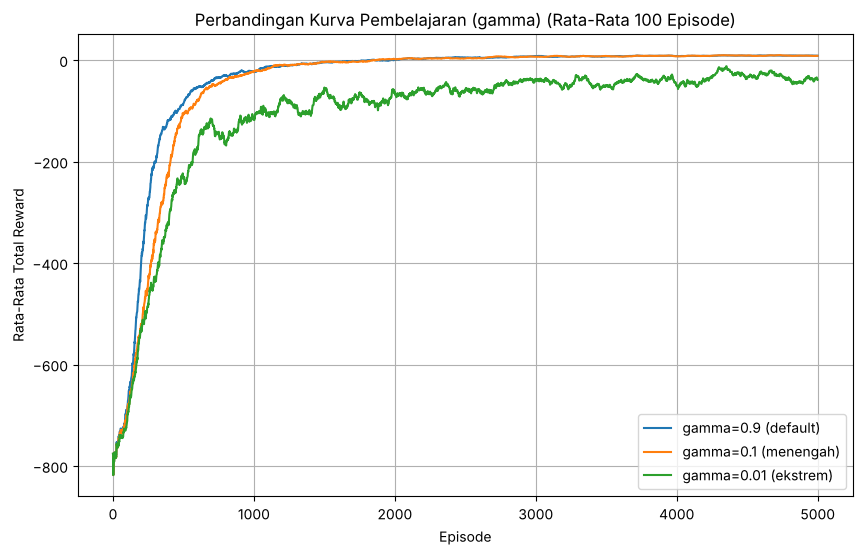

In [19]:
plot_learning_curves(runs, window=100,
                     title=f"Perbandingan Kurva Pembelajaran ({PARAM})",
                     save_path=f"output/eksperimen_{PARAM}_kurva.png")

### Perbandingan kebijakan pada fase mengantar paket (paket di kendaraan, tujuan G)
(model default dibandingkan dengan model ekstrem)

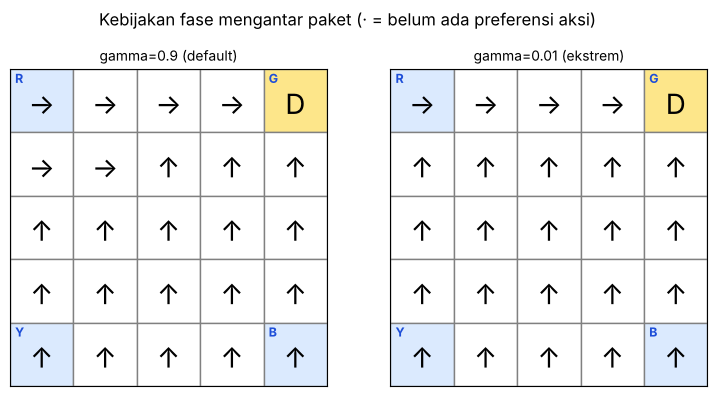

In [20]:
labels = list(runs.keys())
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, label in zip(axes, [labels[0], labels[-1]]):
    plot_policy(runs[label]["q"], pass_loc=4, dest=1, ax=ax, title=label)
fig.suptitle("Kebijakan fase mengantar paket (· = belum ada preferensi aksi)")
fig.savefig(f"output/eksperimen_{PARAM}_policy.png", dpi=150, bbox_inches="tight")
plt.show()

### Perbandingan kebijakan pada fase menuju paket (paket di R, tujuan G)

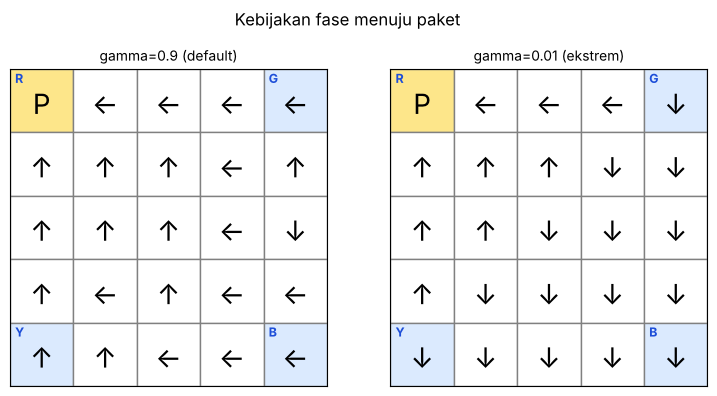

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, label in zip(axes, [labels[0], labels[-1]]):
    plot_policy(runs[label]["q"], pass_loc=0, dest=1, ax=ax, title=label)
fig.suptitle("Kebijakan fase menuju paket")
fig.savefig(f"output/eksperimen_{PARAM}_policy_fase1.png", dpi=150, bbox_inches="tight")
plt.show()

### Tabel ringkasan

Gunakan tabel ini sebagai bahan analisis di laporan (Langkah 5).
Tabel kedua merinci keberhasilan kebijakan dari seluruh 400 state awal yang mungkin.

In [22]:
print(tabel.to_string(index=False))
print()
print(detail.to_string(index=False))
tabel.to_csv(f"output/eksperimen_{PARAM}_ringkasan.csv", index=False)
detail.to_csv(f"output/eksperimen_{PARAM}_rincian.csv", index=False)

               Model  Reward 100 ep. terakhir  Konvergensi (episode)  Sukses greedy (%)  Reward greedy  Langkah rata-rata
 gamma=0.9 (default)                     8.72                   3474              100.0           9.35               11.7
gamma=0.1 (menengah)                     8.50                   3624              100.0           9.38               11.6
gamma=0.01 (ekstrem)                   -38.48                   5000               37.5        -120.52                9.0

               Model State awal berhasil Rute terpendek Paket menunggu (berhasil) Paket di kendaraan (berhasil) Sukses saat pelatihan, per 100 ep. (ep. 1000-5000)
 gamma=0.9 (default)             400/400        394/400                   300/300                       100/100                   100% / 100% / 100% / 100% / 100%
gamma=0.1 (menengah)             400/400        400/400                   300/300                       100/100                   100% / 100% / 100% / 100% / 100%
gamma=0.01 (ekstrem)  